# Step 2: Explore the Data

In [3]:
%pip install tensorflow matplotlib numpy

  Using cached tensorflow-2.21.0-cp312-cp312-manylinux_2_27_x86_64.whl.metadata (4.4 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (3.8 kB)
  Using cached keras-3.15.1-py3-none-any.whl.

# Load the dataset

In [4]:
from tensorflow.keras.datasets import imdb
import numpy as np
import matplotlib.pyplot as plt

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

I0000 00:00:1793281822.921424  945412 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793281822.926010  945412 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793281823.042972  945412 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793281824.200065  945412 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step


/home/abhishek/agentic_ai/nlp_practice/venv/lib/python3.12/site-packages/keras/src/datasets/npz_utils.py:68: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return RestrictedUnpickler(fp).load()


# Check the size

In [5]:
print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))

Training reviews: 25000
Test reviews: 25000


# Look at one raw review

In [6]:
print(X_train[0][:20])
print("Label:", y_train[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Label: 1


### This is what the model sees: just numbers. Label 1 means positive, 0 means negative

In [7]:
word_index = imdb.get_word_index()
reverse = {v + 3: k for k, v in word_index.items()}
reverse.update({0: "<PAD>", 1: "<START>", 2: "<UNK>", 3: "<UNK>"})

print(" ".join(reverse.get(i, "?") for i in X_train[0][:50]))

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved


### Every number is a word. The +3 is because Keras reserves 0, 1, 2 for special tokens

## Do you think all reviews are about the same length?

In [12]:
lengths = [len(x) for x in X_train]

print("Shortest:", min(lengths))
print("Longest:", max(lengths))
print("Average:", np.mean(lengths))
print("Median:", np.median(lengths))

Shortest: 11
Longest: 2494
Average: 238.71364
Median: 178.0


# Plot the histogram

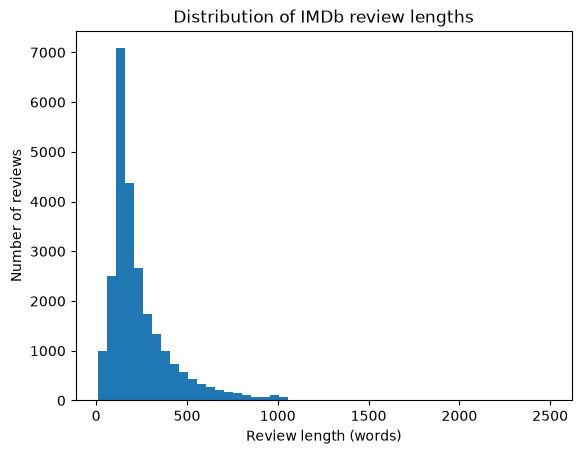

In [9]:
plt.hist(lengths, bins=50)
plt.xlabel("Review length (words)")
plt.ylabel("Number of reviews")
plt.title("Distribution of IMDb review lengths")
plt.show()

### Most reviews are short, but a few are huge. The lengths are all over the place.

## So the data is messy. We can’t feed this to a model as it is. Next, we fix it.

# Step 3: Standardize the Length

### Step 1: Toy example first

In [13]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

toy = [[1, 2, 3], [4, 5], [6]]
print(pad_sequences(toy, maxlen=3))

[[1 2 3]
 [0 4 5]
 [0 0 6]]


### Short ones get filled with zeros. Now every row has the same length

### Step 2: Try truncation

In [14]:
long_one = [[1, 2, 3, 4, 5, 6, 7]]
print(pad_sequences(long_one, maxlen=3))

[[5 6 7]]


### Which part got cut, the start or the end?

### Step 3: Choose maxlen using the data

In [15]:
print(np.percentile(lengths, [50, 75, 90, 95]))

[178. 291. 467. 610.]


### We don’t guess maxlen. We pick it from the data. If we pick the 90th percentile, 9 out of 10 reviews are kept completely.

### Step 4: Apply padding to the real data

In [16]:
maxlen = 256

X_train_pad = pad_sequences(X_train, maxlen=maxlen, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test, maxlen=maxlen, padding="post", truncating="post")

print(X_train_pad.shape)

(25000, 256)


### Before, we had 25,000 lists of different sizes. Now we have one clean table: 25,000 rows, 256 columns.

### Step 5: Verify on one short review

In [17]:
print(len(X_train[0]), "→", len(X_train_pad[0]))
print(X_train_pad[0][-10:])

218 → 256
[0 0 0 0 0 0 0 0 0 0]


### The zeros at the end are padding. They carry no meaning, they only fill space.

## Now every review has the same shape. The model can finally take them in batches.

# Step 4: Active Task

### Two people pick different maxlen values. One picks 100, the other picks 500. Who made the better choice?

### Step 1: Run the comparison

In [18]:
def check_maxlen(maxlen):
    lengths_arr = np.array(lengths)
    kept = np.mean(lengths_arr <= maxlen) * 100
    padded = pad_sequences(X_train, maxlen=maxlen, padding="post", truncating="post")
    zeros = np.mean(padded == 0) * 100
    print(f"maxlen={maxlen}: {kept:.1f}% reviews kept fully | {zeros:.1f}% of values are padding zeros")

for m in [100, 256, 500]:
    check_maxlen(m)

maxlen=100: 11.3% reviews kept fully | 3.5% of values are padding zeros
maxlen=256: 69.9% reviews kept fully | 29.2% of values are padding zeros
maxlen=500: 91.6% reviews kept fully | 55.5% of values are padding zeros


- “At maxlen=100, what are we losing?” (Most reviews get cut, often before the verdict at the end.)
- “At maxlen=500, what are we wasting?” (Memory and training time on zeros.)
- “So who was right?” (Neither. 256 is a middle ground, and the best value depends on the task.)

### Step 2: Optional bonus, pre vs post padding

In [21]:
short = [X_train[0][:5]]
print("pre :", pad_sequences(short, maxlen=10, padding="pre"))
print("post:", pad_sequences(short, maxlen=10, padding="post"))

pre : [[ 0  0  0  0  0  1 14 22 16 43]]
post: [[ 1 14 22 16 43  0  0  0  0  0]]


### Same data, zeros on different sides. For simple models it hardly matters, but for sequence models like LSTMs, post can matter more, so we stay consistent.

## Tokenize so the model can read it, pad so the model can batch it. Next, we’ll turn these numbers into meaning with the Embedding layer.